In [1]:
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from scipy.signal import find_peaks
from tqdm import tqdm

import matplotlib as mpl 
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from dateutil import parser

warnings.filterwarnings('ignore') # Suppress all warnings (use with caution)

##### Config1

In [2]:
# # Blank avec rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1\ELPI+\20250916\Blanc avec rotation\file02.dat' # blanc avec rotation_ELPI

# # RIB-PS avec rotation
# EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_RIB-PS\EP_Normalized_corr.csv")

##### Config1_rep2

In [3]:
# Blank avec rotation
file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config1_rep2\ELPI+\20250917\Blanc avec rotation\file03.dat' # blanc avec rotation_ELPI

# RIB-PS avec rotation
EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Number_corr.csv")
EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config1_rep2_RIB-PS\EP_Normalized_corr.csv")

##### Config2

In [4]:
# # Blank avec rotation
# file = r'c:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\Config2\ELPI+\19-09-2025\Blanc avec rotation\file02.dat' # blanc avec rotation_ELPI

# # RIB-PS avec rotation
# EP_Number_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Number_corr.csv")
# EP_Normalized_corr = pd.read_csv(r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne1\ELPI_corrected_data\Config2_RIB-PS\EP_Normalized_corr.csv")

##### Plots title

In [6]:
speed_correction = 210 # Channel1: Speed: Volt --> RPM
pressure_correction = 1 # Channel2: Pressure: Volt --> bar
temperature_correction = 100 # Channel3: Temperature: Volt --> °C

##### Read blank

In [7]:
# Read channel info from the file header
with open(file, 'r') as f:
    content=f.read().split('\n')
 # Extract channel info from line 13
    physical_channels = np.array(content[12].split('=')[-1].split(',')).astype(float)

# Read physical data from CSV, select columns 0 and 2-15
physical_data = pd.read_csv(file,sep=',',header=36, usecols=np.append([0],np.arange(2,16,1)), index_col=0)

# Assign channel names (skip first beacause we have 15 physical_channels and 14 physical data)
physical_data.columns=physical_channels[1:]
physical_data.dropna(inplace=True)

# Convert index to datetime
physical_data.index = pd.to_datetime(physical_data.index, errors='coerce')
physical_data.index.names =['DateTime']
physical_data.reset_index(drop=False, inplace=True)

# Calculate elapsed time in seconds
physical_data['Time [s]'] = (physical_data['DateTime'] - physical_data['DateTime'].iloc[0]).dt.total_seconds()

In [8]:
columns = np.append([0],np.arange(22,25,1)) # Selecting of: Channel1: Speed Channel2:Pressure Channel3: Temperature
columns = np.append(columns,[36]) # Selecting of: Total number concentration
columns = np.append(columns,np.arange(38,538,1)) # Selecting of: Normalized number concentration from 1 to 500

In [9]:
# Load data
data = pd.read_csv(file, sep=',', header=36, usecols=columns, index_col=0)
data.dropna(inplace=True)

# Convert index to datetime
# data.index = pd.to_datetime(data.index, errors='coerce') # for unknown format
# data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S.%f') # for 10Hz frequency
data.index = pd.to_datetime(data.index, format='%Y/%m/%d %H:%M:%S') # for 1Hz frequency

data.index.names =['DateTime']
data.reset_index(drop=False, inplace=True)

# Rename columns for clarity
data.rename(columns={data.columns[1]:'Speed', data.columns[2]:'Pressure', data.columns[3]:'Temperature'}, inplace=True) 

# Apply correction factors
data['Speed'] = data['Speed']*speed_correction 
data['Pressure'] = data['Pressure']*pressure_correction 
data['Temperature'] = data['Temperature']*temperature_correction 

# Calculate elapsed time
data['Time [s]'] = (data['DateTime'] - data['DateTime'].iloc[0]).dt.total_seconds()

#### Limitations blanks

In [10]:
# Config1
# lmin = 61 #blanc avec rotation_ELPI
# lmax = 3662 #blanc avec rotation_ELPI
# lmin_1 = 65 #blanc avec rotation_AIR_OUTLET_SPEED
# lmax_1 = 3648 #blanc avec rotation_AIR_OUTLET_SPEED

# Config1_rep2
lmin = 75 #blanc avec rotation_ELPI
lmax = 3676 #blanc avec rotation_ELPI
lmin_1 = 38 #blanc avec rotation_AIR_OUTLET_SPEED
lmax_1 = 3639 #blanc avec rotation_AIR_OUTLET_SPEED

# Config2
# lmin = 65 #blanc avec rotation_ELPI
# lmax = 3666 #blanc avec rotation_ELPI
# lmin_1 = 37 #blanc avec rotation_AIR_OUTLET_SPEED
# lmax_1 = 3638 #blanc avec rotation_AIR_OUTLET_SPEED

##### Blank: Creation of new extracted files and show first and last rows

In [11]:
extrait_physical_data = physical_data.iloc[lmin:lmax]
extrait_data = data.iloc[lmin:lmax]

In [12]:
# # Sum across rows for each diameter channel (columns from index 4 onward)
# somme_lignes = extrait_data.iloc[:, 5:-1].sum(axis=0) 
# diameters = somme_lignes.index.astype(float) * 1000 #Convert diameter indices to nanometers

# # Detect peaks in the summed data
# peaks, _ = find_peaks(somme_lignes.values)

# # Extract peak diameters and concentrations
# peak_diameters = diameters[peaks]
# peak_concentrations = somme_lignes.values[peaks]

# # Plot the curve and detected peaks
# plt.figure(figsize=(8, 5))
# plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
# plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# # Annotate each peak
# for dp, conc in zip(peak_diameters, peak_concentrations):
#     plt.annotate(f"{dp:.0f}\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=10, color='red')

# # Enhance plot aesthetics
# plt.title(f"{n}", fontsize=12)
# plt.xscale('log')

# # plt.yscale('log')
# # plt.ylim(1e-3, 1e9)

# plt.ylim(0,7e7)
# # plt.ylim(0,1e5)

# plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
# plt.grid(True, which="both", linestyle="--", linewidth=0.5)
# plt.legend()

# plt.tight_layout()
# plt.show()

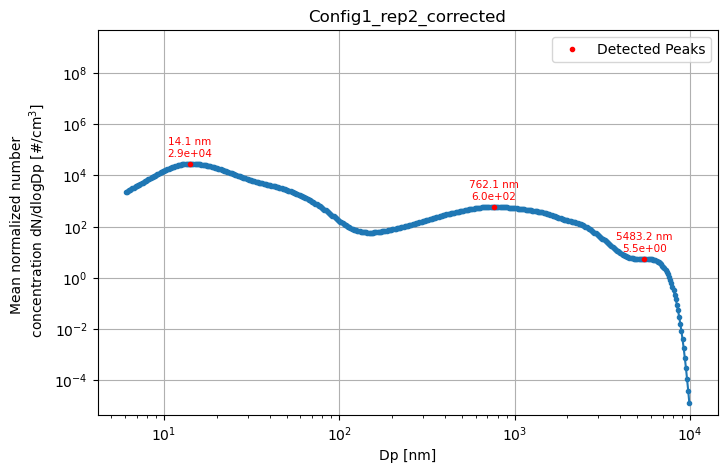

In [13]:
# Compute the sum of rows for each diameter channel
somme_lignes = EP_Normalized_corr.iloc[:, 4:].mean(axis=0) # Select all rows from columns 4 to the end and Sum across rows for each diameter channel
diameters = somme_lignes.index.astype(float) * 1000 # Convert to nm

# Detect all peaks in the summed extrait_data
peaks, _ = find_peaks(somme_lignes.values)

# Extract peak diameters and concentrations
peak_diameters = diameters[peaks]
peak_concentrations = somme_lignes.values[peaks]

# Plot the curve and all detected peaks
plt.figure(figsize=(8, 5))
plt.plot(diameters, somme_lignes, marker='o', markersize=3, linestyle='-', color='tab:blue')
plt.plot(peak_diameters, peak_concentrations, "ro", markersize=3, label='Detected Peaks')

# Annotate each peak
for dp, conc in zip(peak_diameters, peak_concentrations):
    plt.annotate(f"{dp:.1f} nm\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
                 textcoords='offset points', ha='center', fontsize=7.5, color='red')

plt.title(f"{n}_corrected", fontsize=12)
plt.xscale('log')
plt.yscale('log')
plt.ylim(0,5e9)
plt.xlabel("Dp [nm]", fontsize=10)
plt.ylabel("Mean normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.margins(y=0)
plt.grid(True)
plt.legend()
plt.show()

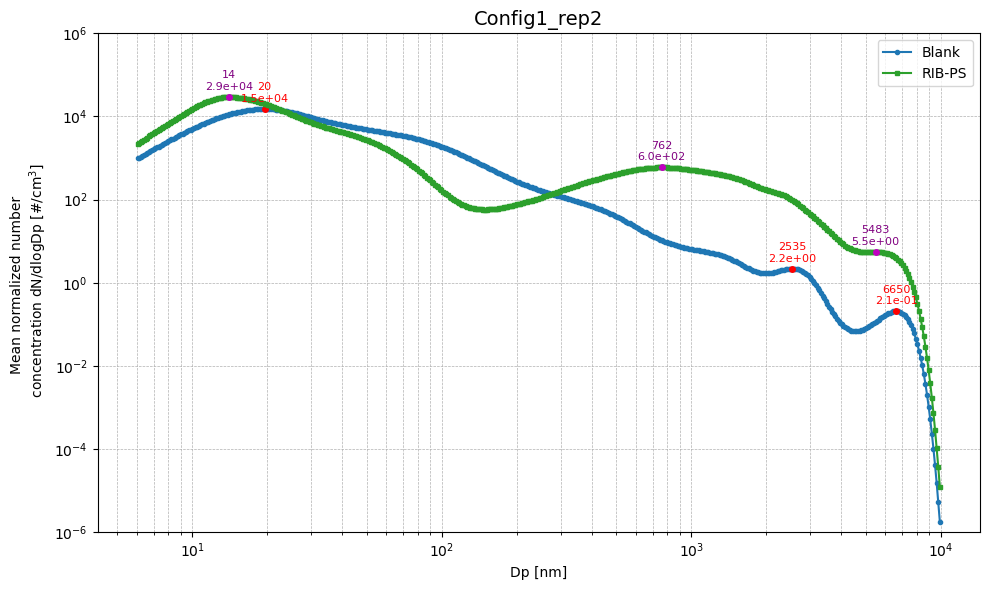

In [14]:
# --- Première série de données ---
# somme_lignes_1 = extrait_data.iloc[:, 5:-1].sum(axis=0)
somme_lignes_1 = extrait_data.iloc[:, 5:-1].mean(axis=0)
diameters_1 = somme_lignes_1.index.astype(float) * 1000  # nm
peaks_1, _ = find_peaks(somme_lignes_1.values)
peak_diameters_1 = diameters_1[peaks_1]
peak_concentrations_1 = somme_lignes_1.values[peaks_1]

# --- Deuxième série de données ---
# somme_lignes_2 = EP_Normalized_corr.iloc[:, 4:].sum(axis=0)
somme_lignes_2 = EP_Normalized_corr.iloc[:, 4:].mean(axis=0)
diameters_2 = somme_lignes_2.index.astype(float) * 1000  # nm
peaks_2, _ = find_peaks(somme_lignes_2.values)
peak_diameters_2 = diameters_2[peaks_2]
peak_concentrations_2 = somme_lignes_2.values[peaks_2]

# --- Plot ---
plt.figure(figsize=(10, 6))

# Courbe 1
plt.plot(diameters_1, somme_lignes_1, marker='o', markersize=3, linestyle='-', color='tab:blue', label="Blank")
plt.plot(peak_diameters_1, peak_concentrations_1, "ro", markersize=4)
for dp, conc in zip(peak_diameters_1, peak_concentrations_1):
    plt.annotate(f"{dp:.0f}\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
                 textcoords='offset points', ha='center', fontsize=8, color='red')

# Courbe 2
plt.plot(diameters_2, somme_lignes_2, marker='s', markersize=3, linestyle='-', color='tab:green', label="RIB-PS")
plt.plot(peak_diameters_2, peak_concentrations_2, "mo", markersize=4)
for dp, conc in zip(peak_diameters_2, peak_concentrations_2):
    plt.annotate(f"{dp:.0f}\n{conc:.1e}", xy=(dp, conc), xytext=(0, 5),
                 textcoords='offset points', ha='center', fontsize=8, color='purple')

# Paramètres communs
plt.xscale('log')
plt.yscale('log')  # ou commenter si vous préférez linéaire
plt.ylim(1e-6, 1e6)   # ajuster selon vos données
plt.xlabel("Dp [nm]", fontsize=10)
# plt.ylabel("Total normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.ylabel("Mean normalized number \n concentration dN/dlogDp [#/cm$^3$]", fontsize=10)
plt.title(f"{n}", fontsize=14)
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend()
plt.tight_layout()
plt.show()
